In [7]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models

In [8]:
VOCAB_SIZE = 1000
MAX_LENGTH = 100
EMBED_DIM = 128
NUM_HEADS = 4
FF_DIM = 256
NUM_LAYERS = 2
BATCH_SIZE = 32
EPOCHS = 2

In [9]:
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.imdb.load_data(num_words=VOCAB_SIZE)
)

In [10]:
X_train = tf.keras.utils.pad_sequences(
    X_train,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_test = tf.keras.utils.pad_sequences(
    X_test,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

In [11]:
class TokenAndPositionEmbedding(layers.Layer):
    def __init__(self, max_length, vocab_size, embed_dim):
        super().__init__()

        self.token_embedding = layers.Embedding(
            input_dim=vocab_size,
            output_dim=embed_dim
        )

        self.position_embedding = layers.Embedding(
            input_dim=max_length,
            output_dim=embed_dim
        )

    def call(self, inputs):
        positions = tf.range(
            start = 0,
            limit = tf.shape(inputs)[-1],
            delta=1
        )

        token_embeddings = self.token_embedding(inputs)
        position_embeddings = self.position_embedding(positions)
        return token_embeddings + position_embeddings

In [12]:
class TransformerBlock(layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim):
        super().__init__()

        self.attention = layers.MultiHeadAttention(
            num_heads=NUM_HEADS,
            key_dim=embed_dim // num_heads
        )

        self.feed_forward = models.Sequential([
            layers.Dense(ff_dim, activation='relu'),
            layers.Dense(embed_dim)
        ])

        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)

        self.dropout1 = layers.Dropout(0.1)
        self.dropout2 = layers.Dropout(0.1)

    def call(self, inputs, training=False):
        attention_output = self.attention(
            query=inputs,
            key=inputs,
            value=inputs
        )

        attention_output = self.dropout1(
            attention_output,
            training=training
        )

        output1 = self.norm1(inputs + attention_output)
        ff_output = self.feed_forward(output1)
        ff_output = self.dropout2(
            ff_output, 
            training=training
        )

        output2 = self.norm2(output1+ff_output)

        return output2

In [13]:
inputs = layers.Input(shape=(MAX_LENGTH, ))
X = TokenAndPositionEmbedding(
    MAX_LENGTH,
    VOCAB_SIZE,
    EMBED_DIM
)(inputs)

for _ in range(NUM_LAYERS):
    X = TransformerBlock(
        EMBED_DIM,
        NUM_HEADS,
        FF_DIM
    )(X)

X = layers.GlobalAveragePooling1D()(X)
X = layers.Dropout(0.2)(X)
X = layers.Dense(64, activation='relu')(X)
X = layers.Dropout(0.2)(X)

outputs = layers.Dense(1, activation='sigmoid')(X)

model = models.Model(inputs=inputs, outputs=outputs)

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ token_and_position_embedding    │ (None, 100, 128)       │       140,800 │
│ (TokenAndPositionEmbedding)     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ (None, 100, 128)       │       132,480 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_1             │ (None, 100, 128)       │       132,480 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 414,081 (1.58 MB)

 Trainable params: 414,081 (1.58 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
history = model.fit(
    X_train,
    y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_split=0.2
)

loss, accuracy = model.evaluate(X_test, y_test)
print("Test Loss : ", loss)
print("Accuracy : ", accuracy)

Epoch 1/2
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 41ms/step - accuracy: 0.7006 - loss: 0.5596 - val_accuracy: 0.7634 - val_loss: 0.4794
Epoch 2/2
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 42ms/step - accuracy: 0.7870 - loss: 0.4576 - val_accuracy: 0.7814 - val_loss: 0.4867
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.7820 - loss: 0.4706
Test Loss :  0.4705684781074524
Accuracy :  0.7819600105285645


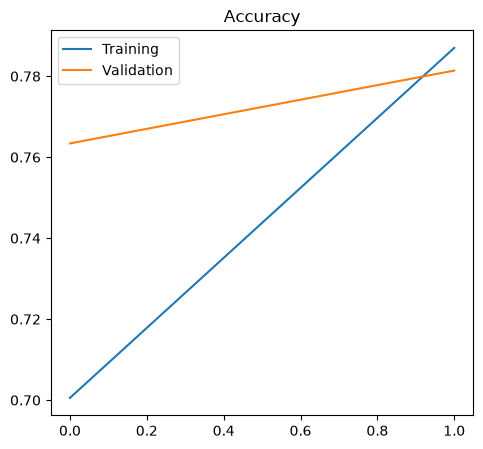

In [15]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label="Training")
plt.plot(history.history['val_accuracy'], label="Validation")
plt.title("Accuracy")
plt.legend()

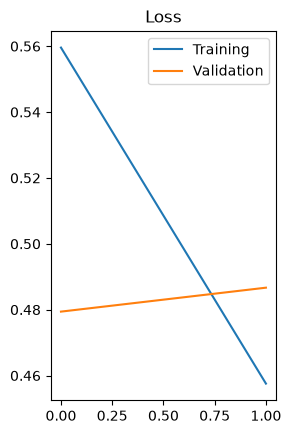

In [16]:

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.legend()

plt.show()